# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../src/troutpy_reproducibility"))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from roi_processing import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Read main path to .zarr file

In [2]:
path_data = (
    "/media/sergio/Meninges/troutpy/raw/merscope_humanbrain/202309251210_HuBrain-FF-SampleF-RC_VMSC000000/region_0"
)

output_path = "/media/sergio/Meninges/troutpy/rois/merscope_hsbrain"

In [3]:
sdata = spatialdata_io.merscope(path_data, mosaic_images=False)

INFO     The column "global_x" has now been renamed to "x"; the column "x" was already present in the dataframe,   
         and will be dropped.                                                                                      
INFO     The column "global_y" has now been renamed to "y"; the column "y" was already present in the dataframe,   
         and will be dropped.                                                                                      


### ROI selection
bb_xmin =0 # mix x 
bb_ymin= 0 #min y
bb_xmax=30 # max x
bb_ymax=30 # max y

img_da=sdata['202309251210_HuBrain-FF-SampleF-RC_VMSC000000_region_0_z3'].scale4
img_da=sdata['202309251210_HuBrain-FF-SampleF-RC_VMSC000000_region_0_z3'].scale4.sel(x=slice(bb_xmin, bb_xmax), y=slice(bb_ymin, bb_ymax)).compute()

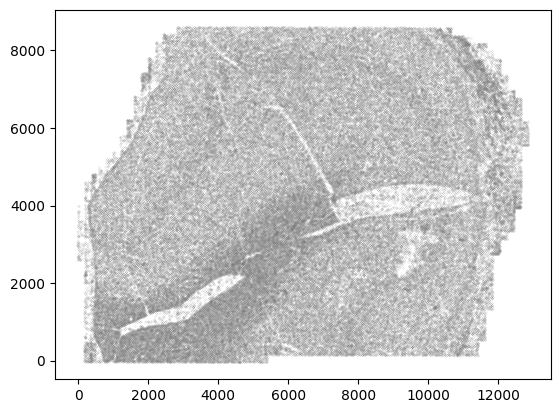

In [4]:
# Visualize using global coordinates
local_coords = sdata["table"].obsm["spatial"]
# In case it's needed, chec transformations
# print(  get_transformation(sdata["nucleus_boundaries"]))
spat = [g[0] for g in sdata["table"].obsm["spatial"]]
spat2 = [g[1] for g in sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=0.01, c="grey")

In [29]:
# ROI selection
bb_xmin = 0  # mix x
bb_ymin = 0  # min y
bb_xmax = 10000  # max x
bb_ymax = 10000  # max y

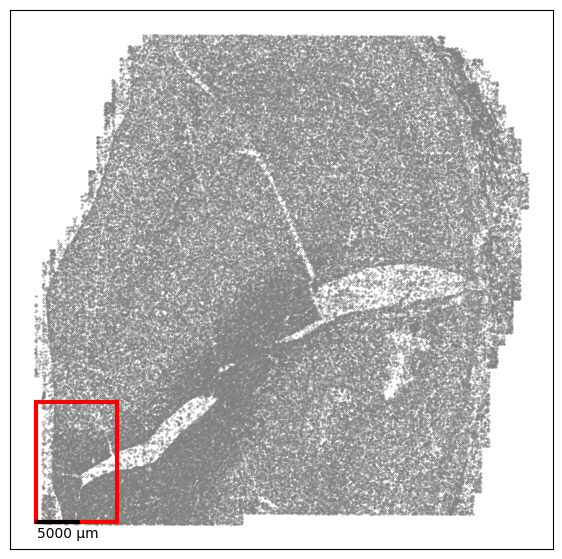

In [30]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata["table"].obsm["spatial"], bb_xmin=bb_xmin, bb_xmax=bb_xmax, bb_ymin=bb_ymin, bb_ymax=bb_ymax
)

In [39]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

In [40]:
cropped_sdata

SpatialData object
├── Points
│     └── '202309251210_HuBrain-FF-SampleF-RC_VMSC000000_region_0_transcripts': DataFrame with shape: (<Delayed>, 9) (2D points)
├── Shapes
│     └── '202309251210_HuBrain-FF-SampleF-RC_VMSC000000_region_0_polygons': GeoDataFrame shape: (1707, 9) (2D shapes)
└── Tables
      └── 'table': AnnData (1707, 960)
with coordinate systems:
    ▸ 'global', with elements:
        202309251210_HuBrain-FF-SampleF-RC_VMSC000000_region_0_transcripts (Points), 202309251210_HuBrain-FF-SampleF-RC_VMSC000000_region_0_polygons (Shapes)

In [ ]:
import spatialdata as sd
import spatialdata.models as models  # alias for sd.models
from spatialdata_io import merscope as _read_merscope
from spatialdata.transformations import ( Affine,set_transformation)


def merscope_converter(path_or_sdata, copy=False, unassigned_tag=-1, z_layers=3, region_name=None, slide_name=None):
    """
    Converts a MERSCOPE SpatialData (or raw path) into the unified format.

    This wraps spatialdata_io.merscope to read MERSCOPE files and then
    restructures Points, Tables, and Images to match xenium_converter output.

    Parameters
    ----------
    path_or_sdata : str / Path or SpatialData
        If str/Path, will be used as the `path` argument to spatialdata_io.merscope.
        Otherwise, must be a pre-loaded SpatialData for a MERSCOPE region.
    copy : bool
        If True, returns a new SpatialData; otherwise modifies in-place.
    unassigned_tag : str
        Tag indicating transcripts not assigned to any cell.
    z_layers : int | list[int]
        Which z-plane(s) to load (default middle layer = 3). :contentReference[oaicite:0]{index=0}
    region_name, slide_name : str, optional
        Passed through to spatialdata_io.merscope for naming.

    Returns
    -------
    SpatialData or None
        Converted object (if copy=True) or None (in-place).
    """
    # 1. Read or accept existing sdata
    if not isinstance(path_or_sdata, sd.SpatialData):
        sdata = _read_merscope(path_or_sdata, z_layers=z_layers, region_name=region_name, slide_name=slide_name)
    else:
        sdata = path_or_sdata

    # 2. Points / Transcripts
    try:
        # detected_transcripts.csv has columns: unlabeled, barcode_id, global_x/y/z, x, y, fov, gene, transcript_id :contentReference[oaicite:1]{index=1}
        transcripts = sdata[list(sdata.points.keys())[0]].compute().reset_index(drop=True)
    except Exception as e:
        raise ValueError("MERSCOPE data must include a Points transcript table.") from e

    # a) Ensure gene is categorical
    if "gene" in transcripts.columns:
        transcripts["gene"] = transcripts["gene"].astype("category")
    else:
        raise KeyError("Expected 'gene' column in MERSCOPE transcripts.")

    # b) No explicit control probes in MERSCOPE—flag all as False (or adjust if you have controls)
    transcripts["control_probe"] = ["Blank" in g for g in transcripts["gene"]]

    # c) Unique transcript IDs as strings
    transcripts["transcript_id"] = transcripts["transcript_id"].astype(str)
    # if transcripts["transcript_id"].duplicated().any():
    #    raise ValueError("Duplicate 'transcript_id' detected; expected unique IDs.")

    # d) Overlap flags
    transcripts["overlaps_nucleus"] = False  # MERSCOPE has no nucleus segmentation by default
    transcripts["overlaps_cell"] = (
        transcripts["cell_id"].apply(lambda x: False if x == unassigned_tag else True)
        if "cell_id" in transcripts.columns
        else False
    )

    # Update Points
    sdata["transcripts"] = models.PointsModel.parse(transcripts)

    # 3. Tables / AnnData
    table = sdata["table"]
    if "cell_id" not in table.obs.columns:
        sdata["table"].obs["cell_id"] = table.obs["EntityID"]
    if table.obs.index.duplicated().any():
        raise ValueError("Non-unique AnnData.obs index; ensure unique cell IDs.")

    # Create raw layer
    if not hasattr(table, "layers") or table.layers is None:
        table.layers = {}
    table.layers["raw"] = table.X.copy()

    # 4. Images → Stainings
    # spatialdata_io.merscope already loads mosaic_z*.tif at multiple scales :contentReference[oaicite:2]{index=2}
    if len(list(sdata.images.keys())) > 0:
        img_key = list(sdata.images.keys())[0]
        sdata[img_key]
        sdata["morphology_focus"] = sdata[img_key]
        del sdata[img_key]
    else:
        print("Not possible to format images, images not found")

    # 5. Format shapes
    shapes_key = list(sdata.shapes.keys())[0]
    sdata["shapes"] = sdata[shapes_key]
    identity = Affine(
    [[1, 0, 0],[0, 1, 0],[0, 0, 1],],
    input_axes=("x", "y"),
    output_axes=("x", "y"),)
    set_transformation(sdata["shapes"], identity, to_coordinate_system="global")

    # delete source info
    del sdata[shapes_key]
    del sdata[list(sdata.points.keys())[0]]

    return sdata if copy else None

In [42]:
merscope_converter(cropped_sdata)

Not possible to format images, images not found


In [43]:
# Save metadata
metadata = generate_metadata(
    sdata=cropped_sdata,
    sample_id="merscope_human_brain",
    species="Homo Sapiens",
    technology="MERSCOPE",
    segmentation_method="MERSCOPE",
    roi_name="brain_ROI",
    tissue="brain",
    disease="alzheimer",
)

In [44]:
# Define output paths
zarr_path = os.path.join(output_path, "data.zarr")
metadata_path = os.path.join(output_path, "metadata.csv")

cropped_sdata.write(zarr_path, overwrite=True)
metadata.to_csv(metadata_path, index=False)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/rois/merscope_hsbrain/data.zarr                                            


In [45]:
cropped_sdata

SpatialData object, with associated Zarr store: /media/sergio/Meninges/troutpy/rois/merscope_hsbrain/data.zarr
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 12) (2D points)
├── Shapes
│     └── 'shapes': GeoDataFrame shape: (1707, 9) (2D shapes)
└── Tables
      └── 'table': AnnData (1707, 960)
with coordinate systems:
    ▸ 'global', with elements:
        transcripts (Points), shapes (Shapes)

In [ ]:
tmp_path = "/media/sergio/Meninges/troutpy/raw/merscope_humanbrain/tmp.zarr"
cropped_sdata.write(tmp_path, overwrite=True)

SpatialData object
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 12) (2D points)
├── Shapes
│     ├── '202309251210_HuBrain-FF-SampleF-RC_VMSC000000_region_0_polygons': GeoDataFrame shape: (69, 9) (2D shapes)
│     └── 'shapes': GeoDataFrame shape: (69, 9) (2D shapes)
└── Tables
      └── 'table': AnnData (69, 960)
with coordinate systems:
    ▸ 'global', with elements:
        transcripts (Points), 202309251210_HuBrain-FF-SampleF-RC_VMSC000000_region_0_polygons (Shapes), shapes (Shapes)

In [48]:
sdata["segmented"] = sd.models.ShapesModel.parse(gdf)

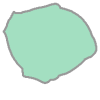

In [58]:
sdata["segmented"]["geometry"][10]

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' do disable this    
         behaviour.                                                                                                
INFO     alpha component of given RGBA value for outline color is discarded, because outline_alpha takes precedent.


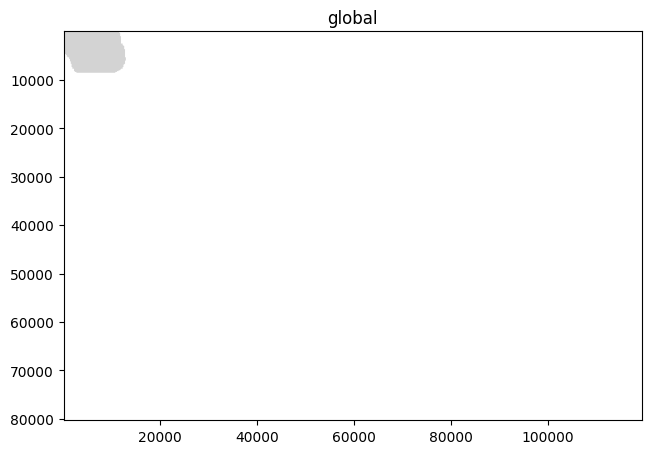

In [18]:
import spatialdata_plot as sdp  # noqa: F401

sdata.pl.render_shapes().pl.show()

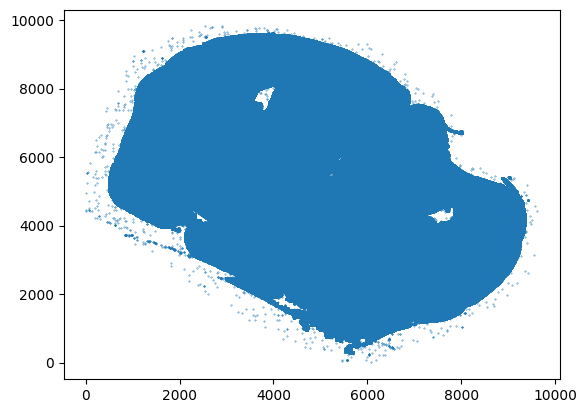

In [ ]:
tran = sdata["raw_msbrain_receptormap_r2s2_transcripts"].compute()
plt.scatter(tran["x"], tran["y"], s=0.02)

In [64]:
sdata_shapes = sdata.aggregate(
    values="raw_msbrain_receptormap_r2s2_transcripts", by="segmented", value_key="gene", agg_func="count"
)
sdata_shapes

SpatialData object
├── Shapes
│     └── 'segmented': GeoDataFrame shape: (78329, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (78329, 649)
with coordinate systems:
    ▸ 'global', with elements:
        segmented (Shapes)

<78329x649 sparse matrix of type '<class 'numpy.int64'>'
	with 0 stored elements in Compressed Sparse Row format>

In [65]:
sc.pl.spatial(sdata_shapes["table"], spot_size=20)

KeyError: "Could not find 'spatial' or 'X_spatial' in .obsm"

In [42]:
# after you’ve built your flat GeoDataFrame `gdf`
# assume you kept a "z_index" column
sdata.shapes["cell_boundaries"] = gdf

ValueError: :class:`geopandas.GeoDataFrame` does not contain `transform`. Please use ShapesModel.parse() to construct data that is guaranteed to be valid.

In [41]:
sdata["raw_msbrain_receptormap_r2s2_transcripts"].compute()

,x,y,barcode_id,fov,Unnamed: 0,gene,global_z
0,94.497154,5830.9800,22,0,0,Adgre1,0.0
1,27.500680,5546.4565,22,2,1,Adgre1,0.0
2,29.215889,5546.4487,22,2,2,Adgre1,0.0
3,45.469160,5569.9966,22,2,3,Adgre1,3.0
4,29.123753,5546.3000,131,2,4,Gpr22,0.0
...,...,...,...,...,...,...,...
981016,9483.610000,4038.2480,131,1637,61189762,Gpr22,0.0
981017,9463.007000,4119.2437,447,1637,61189763,Ephb6,0.0
981018,9475.143000,4296.1230,181,1638,61189764,Mrgpra3,0.0
981019,9615.522000,4416.0967,131,1639,61189765,Gpr22,0.0


In [6]:
sdata["raw_msbrain_receptormap_r2s2_transcripts"].compute()

,x,y,Unnamed: 0,barcode_id,fov,gene,global_z
0,94.497154,5830.9800,0,22,0,Adgre1,0.0
1,27.500680,5546.4565,1,22,2,Adgre1,0.0
2,29.215889,5546.4487,2,22,2,Adgre1,0.0
3,45.469160,5569.9966,3,22,2,Adgre1,3.0
4,29.123753,5546.3000,4,131,2,Gpr22,0.0
...,...,...,...,...,...,...,...
981016,9483.610000,4038.2480,61189762,131,1637,Gpr22,0.0
981017,9463.007000,4119.2437,61189763,447,1637,Ephb6,0.0
981018,9475.143000,4296.1230,61189764,181,1638,Mrgpra3,0.0
981019,9615.522000,4416.0967,61189765,131,1639,Gpr22,0.0


In [3]:
troutpy.pp.cosmx_converter(sdata)

Global Image Canvas Dimensions: Width = 37811, Height = 46004
Image stitching complete!
Global Label Canvas Dimensions: Width = 32134, Height = 46004
Label stitching complete!


In [5]:
sdata["transcripts"]

,gene,cell_ID,z_raw,y,x,fov,CellComp,local_x,local_y,transcript_id,overlaps_cell,overlaps_nuclei,control_probe
npartitions=1,,,,,,,,,,,,,
0,category[known],int64,int64,float64,float64,int64,string,float64,float64,int64,bool,bool,bool
9531240,...,...,...,...,...,...,...,...,...,...,...,...,...


## Deprecated code for converting cosmx data to standard troutpy data

In [ ]:
import numpy as np
import xarray as xr
from spatial_image import to_spatial_image

# Assuming each tile is the same size (e.g., from tile "1_image")
tile_ids = list(sdata.images.data.keys())
tile_ids_image = tile_ids
sample_tile = sdata[tile_ids[0]]
tile_height = sample_tile.data.shape[1]  # e.g., 3648
tile_width = sample_tile.data.shape[2]  # e.g., 5472

# Extract global offsets from the transformation matrix for each tile
x_offsets = {}
y_offsets = {}
for tid in tile_ids:
    # Access the transformation matrix
    transform_matrix = sdata[tid].transform["global"].matrix
    x_offsets[tid] = transform_matrix[0, 2]
    y_offsets[tid] = transform_matrix[1, 2]

# Compute the global canvas extents using the offsets
global_x_min = min(x_offsets.values())
global_y_min = min(y_offsets.values())
global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

canvas_width = int(np.ceil(global_x_max - global_x_min))
canvas_height = int(np.ceil(global_y_max - global_y_min))

print("Global Canvas Dimensions: Width =", canvas_width, ", Height =", canvas_height)

# Initialize a canvas for the stitched image (assuming 3-channel RGB)
global_image_canvas = np.zeros((3, canvas_height, canvas_width), dtype=np.uint8)

# Stitch each tile into the global canvas
for tid in tile_ids:
    # Compute the offset relative to the global minimum positions
    x_offset = int(np.round(x_offsets[tid] - global_x_min))
    y_offset = int(np.round(y_offsets[tid] - global_y_min))

    # Retrieve the tile image data (expected shape: (3, tile_height, tile_width))
    tile_image = sdata[tid].data

    # Place the tile into the global canvas
    global_image_canvas[:, y_offset : y_offset + tile_height, x_offset : x_offset + tile_width] = tile_image

# Convert the stitched image array to an xarray DataArray and then to a spatial image object
stitched_da = xr.DataArray(global_image_canvas, dims=("c", "y", "x"))

print("Stitching complete!")

Global Canvas Dimensions: Width = 37811 , Height = 46004
Stitching complete!


In [ ]:
import numpy as np
import xarray as xr
# from spatialdata import Label

# Assuming each label tile is the same size (e.g., from tile "1_labels")
tile_ids = list(sdata.labels.data.keys())
# sample_tile = sdata[tile_ids[0]]
sample_label = sdata[tile_ids[0]]
tile_height = sample_label.data.shape[0]  # (y dimension), e.g., 3648
tile_width = sample_label.data.shape[1]  # (x dimension), e.g., 5472

# Extract global offsets for each tile from the corresponding image's transformation matrix.
# (Labels are aligned with images, so we use sdata[f"{tid}_image"].transform)
x_offsets = {}
y_offsets = {}
for tid in tile_ids:
    # Get the transformation matrix from the associated image tile
    transform_matrix = sdata[f"{tid}"].transform["global"].matrix
    x_offsets[tid] = transform_matrix[0, 2]
    y_offsets[tid] = transform_matrix[1, 2]

# Compute the overall extents of the global canvas for labels
global_x_min = min(x_offsets.values())
global_y_min = min(y_offsets.values())
global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

canvas_width = int(np.ceil(global_x_max - global_x_min))
canvas_height = int(np.ceil(global_y_max - global_y_min))

print("Global Canvas Dimensions (Labels): Width =", canvas_width, ", Height =", canvas_height)

# Initialize a canvas for the stitched label image
global_label_canvas = np.zeros((canvas_height, canvas_width), dtype=sample_label.data.dtype)

# Place each label tile into the global canvas using its computed offsets
for tid in tile_ids:
    x_offset = int(np.round(x_offsets[tid] - global_x_min))
    y_offset = int(np.round(y_offsets[tid] - global_y_min))

    tile_label = sdata[f"{tid}"].data  # shape: (tile_height, tile_width)

    # Place the tile's labels into the global canvas
    global_label_canvas[y_offset : y_offset + tile_height, x_offset : x_offset + tile_width] = tile_label

# Wrap the stitched labels into an xarray DataArray
stitched_labels_da = xr.DataArray(global_label_canvas, dims=("y", "x"))

# Optionally, convert the DataArray to a proper Label object (if using spatialdata Label methods)
# stitched_label_object = Label.from_xarray(stitched_labels_da)

print("Label stitching complete!")

Global Canvas Dimensions (Labels): Width = 32134 , Height = 46004
Label stitching complete!


In [155]:
import pandas as pd

alldf = []
for id in tile_ids:
    transcripts = sdata[id].compute()
    alldf.append(transcripts)

# Concatenate all tile dataframes
alltranscripts = pd.concat(alldf, ignore_index=True)

# Store original local coordinates
alltranscripts["local_x"] = alltranscripts["x"]
alltranscripts["local_y"] = alltranscripts["y"]

del alltranscripts["y"]
del alltranscripts["x"]

# Rename global coordinates and target
alltranscripts.rename(columns={"x_global_px": "x", "y_global_px": "y", "target": "gene"}, inplace=True)

# Generate unique transcript_id
alltranscripts["transcript_id"] = [i for i in range(len(alltranscripts))]

# overlaps_cell is True if cell_ID is not 0
alltranscripts["overlaps_cell"] = alltranscripts["cell_ID"] != 0

# overlaps_nuclei is True if CellComp is 'Nuclear'
alltranscripts["overlaps_nuclei"] = alltranscripts["CellComp"] == "Nuclear"
alltranscripts["overlaps_nuclei"].fillna(False, inplace=True)
alltranscripts["overlaps_nuclei"] = alltranscripts["overlaps_nuclei"].astype(bool)

# control_probe is True if gene starts with 'NegPrb'
alltranscripts["control_probe"] = alltranscripts["gene"].str.startswith("NegPrb")

In [ ]:
### format sdata table
sdata["table"].obsm["spatial"] = sdata["table"].obsm["global"]

In [177]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import spatialdata as sd
import spatialdata_plot as sdp  # noqa: F401
import squidpy as sq
from shapely.geometry import Point
from spatialdata.models import Image2DModel, Labels2DModel

img_for_sdata = Image2DModel.parse(data=stitched_da, scale_factors=(2, 2), c_coords=sdata[tile_ids_image[0]].c.data)
parsed_transcripts = sd.models.PointsModel.parse(alltranscripts)
labels_for_sdata = Labels2DModel.parse(data=stitched_labels_da, scale_factors=(2, 2))

sdata2 = sd.SpatialData(
    images={"morphology_focus": img_for_sdata},
    labels={"labels": labels_for_sdata},
    tables={"adata": sdata["table"]},
    points={"transcripts": parsed_transcripts},
)

NameError: name 'tile_ids_image' is not defined

In [ ]:
import numpy as np
import xarray as xr
from spatial_image import to_spatial_image
import pandas as pd
import spatialdata as sd
from spatialdata.models import Image2DModel, Labels2DModel
from typing import Optional


def process_image_data(sdata: sd.SpatialData) -> xr.DataArray:
    """
    Stitches image tiles from SpatialData object into a single global image.

    Args:
        sdata: The input SpatialData object containing image tiles.

    Returns:
        An xarray DataArray representing the stitched global image.
    """
    tile_ids = list(sdata.images.data.keys())
    sample_tile = sdata[tile_ids[0]]
    tile_height = sample_tile.data.shape[1]
    tile_width = sample_tile.data.shape[2]

    x_offsets = {}
    y_offsets = {}
    for tid in tile_ids:
        transform_matrix = sdata[tid].transform["global"].matrix
        x_offsets[tid] = transform_matrix[0, 2]
        y_offsets[tid] = transform_matrix[1, 2]

    global_x_min = min(x_offsets.values())
    global_y_min = min(y_offsets.values())
    global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
    global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

    canvas_width = int(np.ceil(global_x_max - global_x_min))
    canvas_height = int(np.ceil(global_y_max - global_y_min))

    print(f"Global Image Canvas Dimensions: Width = {canvas_width}, Height = {canvas_height}")

    global_image_canvas = np.zeros((3, canvas_height, canvas_width), dtype=np.uint8)

    for tid in tile_ids:
        x_offset = int(np.round(x_offsets[tid] - global_x_min))
        y_offset = int(np.round(y_offsets[tid] - global_y_min))
        tile_image = sdata[tid].data
        global_image_canvas[:, y_offset : y_offset + tile_height, x_offset : x_offset + tile_width] = tile_image

    stitched_da = xr.DataArray(global_image_canvas, dims=("c", "y", "x"))
    print("Image stitching complete!")
    return stitched_da


def process_label_data(sdata: sd.SpatialData) -> xr.DataArray:
    """
    Stitches label tiles from SpatialData object into a single global label image.

    Args:
        sdata: The input SpatialData object containing label tiles.

    Returns:
        An xarray DataArray representing the stitched global label image.
    """
    tile_ids = list(sdata.labels.data.keys())
    sample_label = sdata[tile_ids[0]]
    tile_height = sample_label.data.shape[0]
    tile_width = sample_label.data.shape[1]

    x_offsets = {}
    y_offsets = {}
    for tid in tile_ids:
        transform_matrix = sdata[f"{tid}"].transform["global"].matrix
        x_offsets[tid] = transform_matrix[0, 2]
        y_offsets[tid] = transform_matrix[1, 2]

    global_x_min = min(x_offsets.values())
    global_y_min = min(y_offsets.values())
    global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
    global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

    canvas_width = int(np.ceil(global_x_max - global_x_min))
    canvas_height = int(np.ceil(global_y_max - global_y_min))

    print(f"Global Label Canvas Dimensions: Width = {canvas_width}, Height = {canvas_height}")

    global_label_canvas = np.zeros((canvas_height, canvas_width), dtype=sample_label.data.dtype)

    for tid in tile_ids:
        x_offset = int(np.round(x_offsets[tid] - global_x_min))
        y_offset = int(np.round(y_offsets[tid] - global_y_min))
        tile_label = sdata[f"{tid}"].data
        global_label_canvas[y_offset : y_offset + tile_height, x_offset : x_offset + tile_width] = tile_label

    stitched_labels_da = xr.DataArray(global_label_canvas, dims=("y", "x"))
    print("Label stitching complete!")
    return stitched_labels_da


def process_transcript_data(sdata: sd.SpatialData) -> pd.DataFrame:
    """
    Processes transcript data from SpatialData object, concatenating tiles and
    performing necessary transformations.

    Args:
        sdata: The input SpatialData object containing transcript data.

    Returns:
        A pandas DataFrame containing the processed transcript data.
    """
    tile_ids = list(sdata.points.data.keys())  # changed from sdata.labels to sdata.images
    alldf = []
    for id in tile_ids:
        transcripts = sdata[id].compute()
        alldf.append(transcripts)

    alltranscripts = pd.concat(alldf, ignore_index=True)

    alltranscripts["local_x"] = alltranscripts["x"]
    alltranscripts["local_y"] = alltranscripts["y"]

    del alltranscripts["y"]
    del alltranscripts["x"]

    alltranscripts.rename(columns={"x_global_px": "x", "y_global_px": "y", "target": "gene"}, inplace=True)

    alltranscripts["transcript_id"] = [i for i in range(len(alltranscripts))]
    alltranscripts["overlaps_cell"] = alltranscripts["cell_ID"] != 0
    alltranscripts["overlaps_nuclei"] = alltranscripts["CellComp"] == "Nuclear"
    alltranscripts["overlaps_nuclei"].fillna(False, inplace=True)
    alltranscripts["overlaps_nuclei"] = alltranscripts["overlaps_nuclei"].astype(bool)
    alltranscripts["control_probe"] = alltranscripts["gene"].str.startswith("NegPrb")

    sdata["table"].obsm["spatial"] = sdata["table"].obsm["global"]
    return alltranscripts


def cosmx_converter(sdata: sd.SpatialData, copy: bool = False) -> sd.SpatialData:
    """
    Converts CosMX data from a SpatialData object into a new SpatialData object
    with processed image, label, and transcript data.

    Args:
        sdata: The input SpatialData object containing the raw CosMX data.
        copy: If True, returns a copy of the SpatialData object with the
            converted data. If False, modifies the original SpatialData object
            in place and returns it.

    Returns:
        A SpatialData object containing the converted data.  This is a *new*
        SpatialData object if copy is True, otherwise it's the *same* object
        as the input (modified in place).
    """

    sdata_out = sdata

    stitched_da = process_image_data(sdata_out)
    stitched_labels_da = process_label_data(sdata_out)
    parsed_transcripts = sd.models.PointsModel.parse(process_transcript_data(sdata_out))

    sdata_out.images = {
        "morphology_focus": Image2DModel.parse(
            data=stitched_da, scale_factors=(2, 2), c_coords=sdata_out[list(sdata_out.images.keys())[0]].c.data
        )
    }  # changed sdata to sdata_out
    sdata_out.labels = {
        "labels": Labels2DModel.parse(data=stitched_labels_da, scale_factors=(2, 2))
    }  # changed sdata to sdata_out
    sdata_out.points = {"transcripts": parsed_transcripts}

    return sdata if copy else None

In [ ]:
sdata["1_image"].transform["global"]

Affine (x, y -> x, y)
    [ 1.00000000e+00 -1.37253336e-16  1.71555556e+04]
    [-1.40753753e-16  1.00000000e+00  1.69755556e+05]
    [0. 0. 1.]

In [ ]:
sdata["1_image"].transform["global"]

In [9]:
from spatial_image import to_spatial_image
from spatialdata import SpatialData
import xarray as xr
import numpy as np

# Example for stitching
stitched_image = np.zeros((3, H_total, W_total))  # e.g. (3, 3648 * 5, 5472 * 4)
# Place each tile in its correct (row, col) position
stitched_image[:, r * 3648 : (r + 1) * 3648, c * 5472 : (c + 1) * 5472] = image_tile

# Wrap in DataArray
stitched_da = xr.DataArray(stitched_image, dims=("c", "y", "x"))
image = to_spatial_image(stitched_da, scale=[1.0, 1.0])

NameError: name 'H_total' is not defined

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' do disable this    
         behaviour.                                                                                                


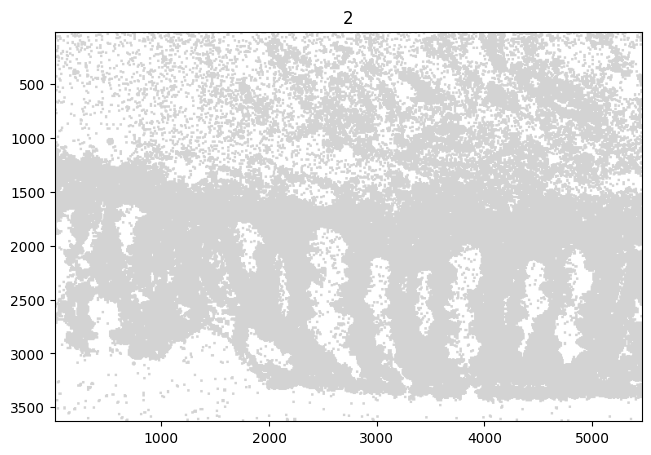

In [10]:
sdata.pl.render_points().pl.show(coordinate_systems=["2"])

INFO     Rasterizing image for faster rendering.                                                                   


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.2944162].


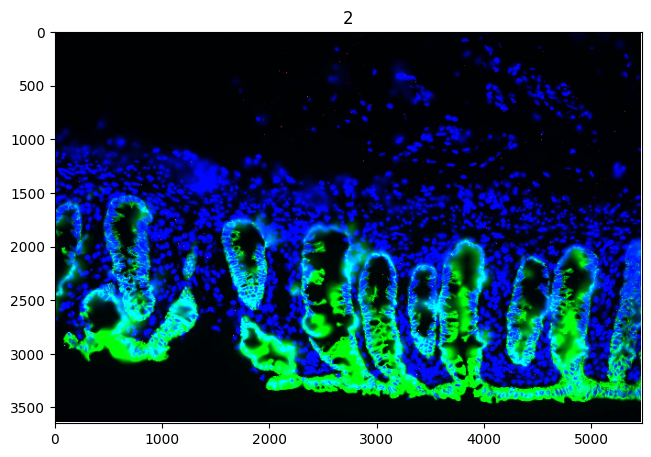

In [8]:
import spatialdata_plot

sdata.pl.render_images().pl.show(coordinate_systems=["2"])

In [14]:
sdata["table"].var

""
AATK
ABL1
ABL2
ACE
ACE2
...
NegPrb19
NegPrb20
NegPrb21
NegPrb22


In [34]:
inpath = "/media/sergio/Meninges/troutpy/xenium_msbrain_300/msbrain.zarr"
sdata = sd.read_zarr(inpath)

output_path = "/media/sergio/Meninges/troutpy/rois/xenium_msbrain_300"

We decide to keep the data in a unified scale (um), which then can be transformated to 'global' coordinates using the according transformation. This global transformation is specially useful for matching the sales of transcripts with ie images

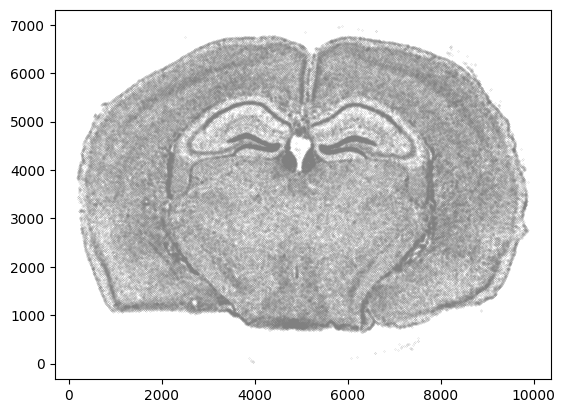

In [35]:
# Visualize using global coordinates
local_coords = sdata["table"].obsm["spatial"]
# In case it's needed, chec transformations
# print(  get_transformation(sdata["nucleus_boundaries"]))
spat = [g[0] for g in sdata["table"].obsm["spatial"]]
spat2 = [g[1] for g in sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=0.01, c="grey")

In [36]:
# ROI selection
bb_xmin = 12000  # mix x
bb_ymin = 18000  # min y
bb_xmax = 23000  # max x
bb_ymax = 35000  # max y

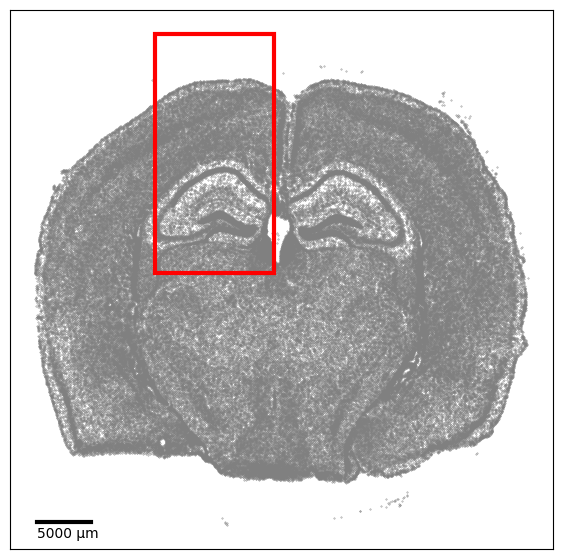

In [37]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata["table"].obsm["spatial"], bb_xmin=bb_xmin, bb_xmax=bb_xmax, bb_ymin=bb_ymin, bb_ymax=bb_ymax
)

Next, we select the ROI of interest

In [38]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

In [ ]:
# Save metadata
metadata = generate_and_save_metadata(
    sdata=cropped_sdata,
    sample_id="mouse_brain_sample1",
    species="Mus musculus",
    technology="Visium",
    segmentation_method="nuclei_expanded",
    roi_name="cortex_ROI",
    tissue="brain",
    disease="control",
)

# Define output paths

zarr_path = os.path.join(output_path, "data.zarr")
metadata_path = os.path.join(output_path, "metadata.csv")

cropped_sdata.write(zarr_path, overwrite=True)
metadata.to_csv(metadata_path, index=False)

ValueError: Attempt to save array to zarr with irregular chunking, please call `arr.rechunk(...)` first.

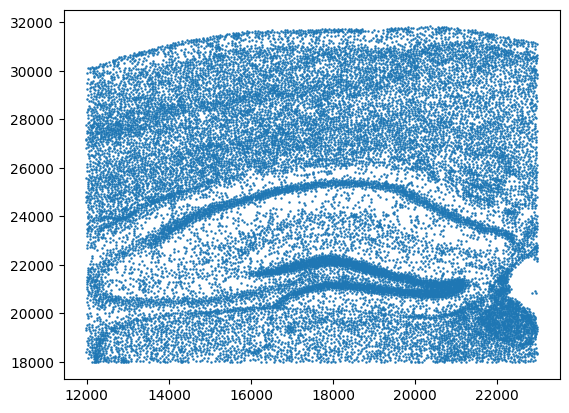

In [ ]:
spat = [g[0] * 4.7 for g in cropped_sdata["table"].obsm["spatial"]]
spat2 = [g[1] * 4.7 for g in cropped_sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=0.6, c="grey")

In [39]:
sdata["table"].var

,feature_types,genome,gene_names
gene_ids,,,
ENSMUSG00000026090,Gene Expression,Unknown,2010300C02Rik
ENSMUSG00000032281,Gene Expression,Unknown,Acsbg1
ENSMUSG00000035783,Gene Expression,Unknown,Acta2
ENSMUSG00000000530,Gene Expression,Unknown,Acvrl1
ENSMUSG00000036545,Gene Expression,Unknown,Adamts2
...,...,...,...
ENSMUSG00000045648,Gene Expression,Unknown,Vwc2l
ENSMUSG00000039474,Gene Expression,Unknown,Wfs1
ENSMUSG00000050919,Gene Expression,Unknown,Zfp366


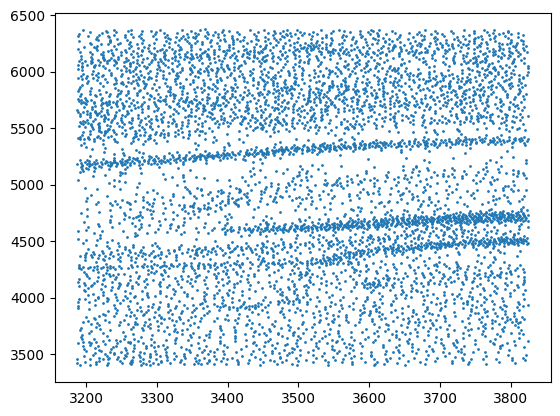

In [22]:
spat = [g[0] for g in sdata["table"].obsm["spatial"]]
spat2 = [g[1] for g in sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=1)

In [23]:
transcripts = sdata["transcripts"].compute()
transcripts.reset_index(drop=True, inplace=True)
sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)